In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os, sys
# sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
sys.path.append('/home/jiayu/SeismoApnea4Ubicomp_Feb/Code')
sys.path.append('/home/jiayu/SeismoApnea4Ubicomp_Feb')
from scipy.signal import butter, filtfilt
from scipy.stats import kurtosis


In [2]:
def low_pass_filter(data, Fs, low, order):
	b, a = butter(order, low/(Fs * 0.5), 'low')

	if data.ndim == 1:
		N = len(data)
		padded = np.pad(data, (N, N), mode='reflect')
	elif data.ndim == 2:
		N = data.shape[1]
		padded = np.pad(data, ((0, 0), (N, N)), mode='reflect')
	
	filtered_data = filtfilt(b, a, padded)

	if data.ndim == 1:
		filtered_data = filtered_data[N:-N]
	elif data.ndim == 2:
		filtered_data = filtered_data[:, N:-N]
	
	return filtered_data

def cal_fft(data, Fs):
	N = len(data)
	freqs = np.fft.rfftfreq(N, d=1/Fs)
	fft_values = np.fft.rfft(data)
	return freqs, fft_values


def zero_crossing_rate(x):
    x = np.array(x)
    crossings = np.where(np.diff(np.sign(x)))[0]
    zcr = len(crossings) / len(x)
    return zcr


def normalize_signal(signal):
	mean = np.mean(signal)
	std = np.std(signal)
	if std > 0:
		return (signal - mean) / std
	else:
		return signal - mean
	

def align_by_lag_crop(x, y, lag_samples):
    if lag_samples > 0:
        x_aligned = x[:-lag_samples]
        y_aligned = y[lag_samples:]
    elif lag_samples < 0:
        lag_abs = abs(lag_samples)
        x_aligned = x[lag_abs:]
        y_aligned = y[:-lag_abs]
    else:
        x_aligned = x.copy()
        y_aligned = y.copy()


    return x_aligned, y_aligned

In [3]:
all_data = []
for i in range(1, 5):
	data_file_path = f'/home/jiayu/SeismoApnea4Ubicomp_Feb/Data/fold_data_p109_MTL_60s/fold{i}.npy'
	all_data.append(np.load(data_file_path))
all_data = np.concatenate(all_data, axis=0)
np.unique(all_data[:, -4])

array([  1.,   2.,   3.,   4.,   5.,   7.,   8.,   9.,  10.,  11.,  12.,
        14.,  15.,  16.,  17.,  18.,  19.,  22.,  23.,  24.,  25.,  26.,
        27.,  28.,  29.,  30.,  31.,  32.,  33.,  34.,  35.,  36.,  38.,
        39.,  40.,  41.,  42.,  44.,  45.,  46.,  48.,  50.,  51.,  52.,
        53.,  55.,  56.,  57.,  58.,  59.,  60.,  63.,  64.,  66.,  68.,
        69.,  71.,  81.,  83.,  84.,  86.,  87.,  90.,  91.,  92.,  93.,
        95.,  96.,  97.,  98.,  99., 101., 102., 104., 105., 106., 107.,
       108., 110., 111., 114., 116., 117., 118., 119., 120., 121., 122.,
       123., 127., 130., 131., 134., 136., 137., 138., 141., 143., 144.,
       146., 148., 150., 151., 152., 153., 154., 155., 156., 157.])

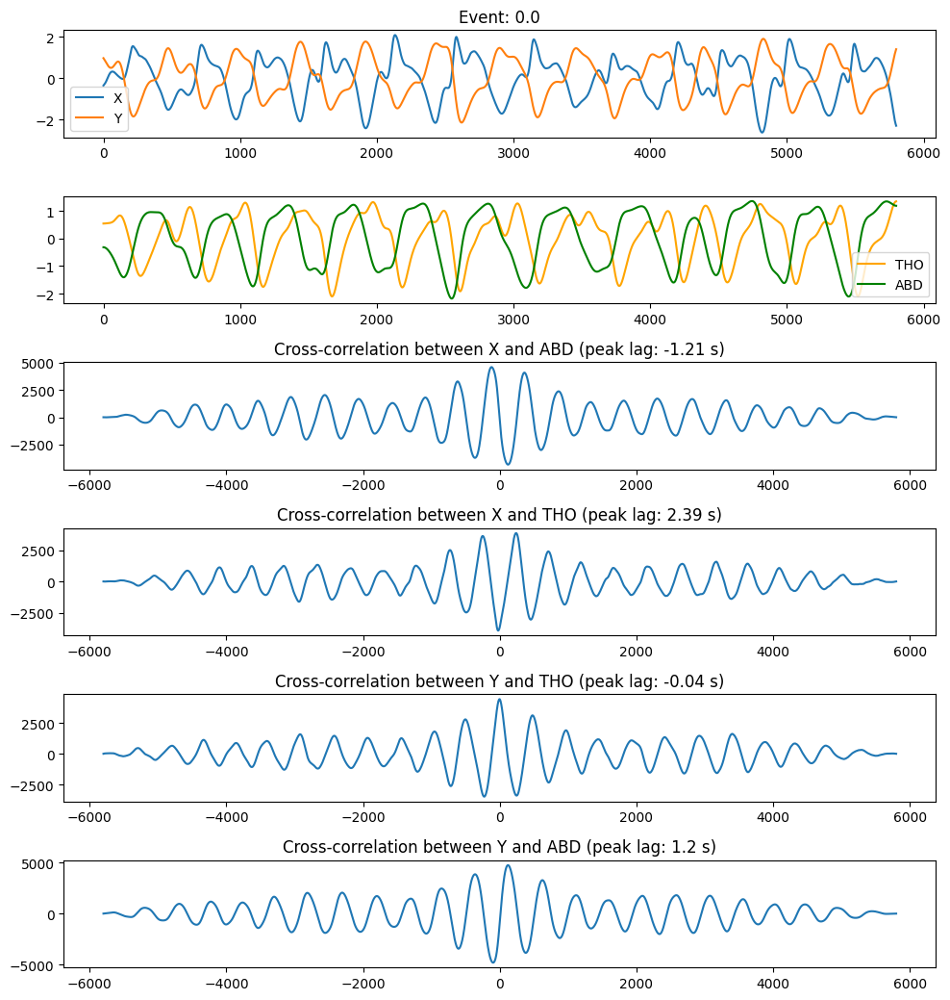

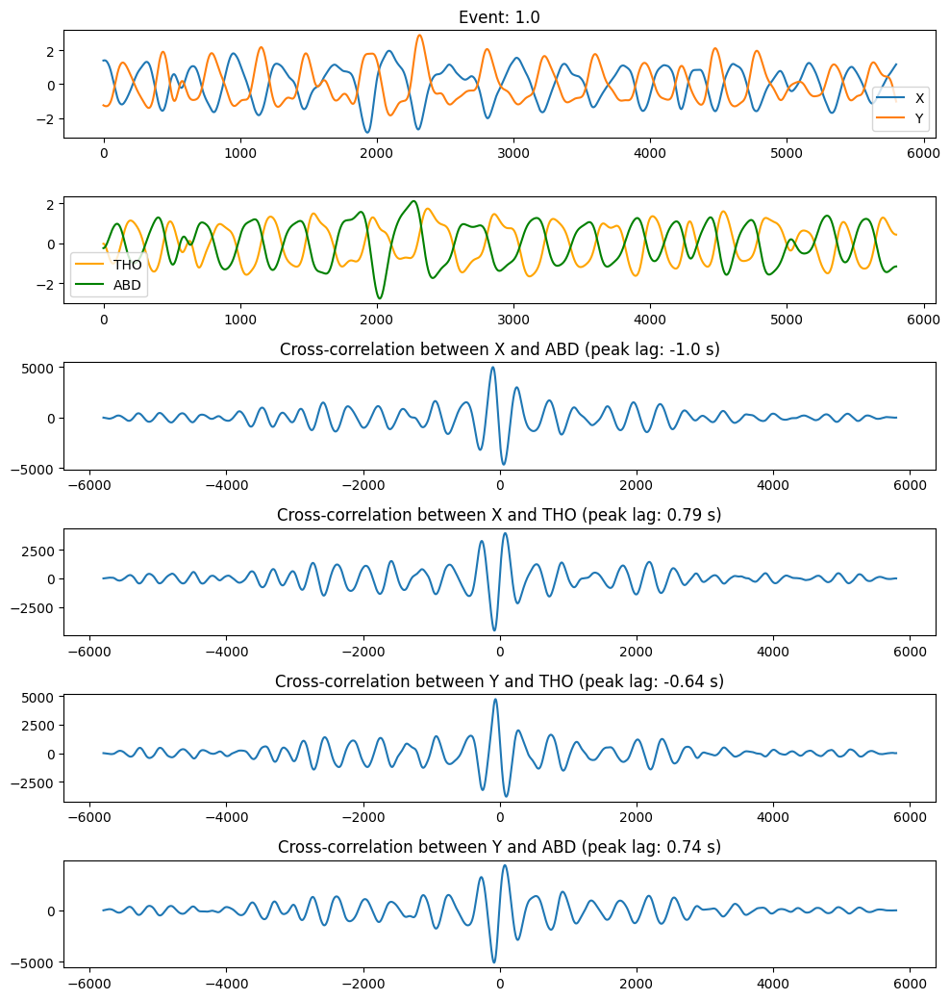

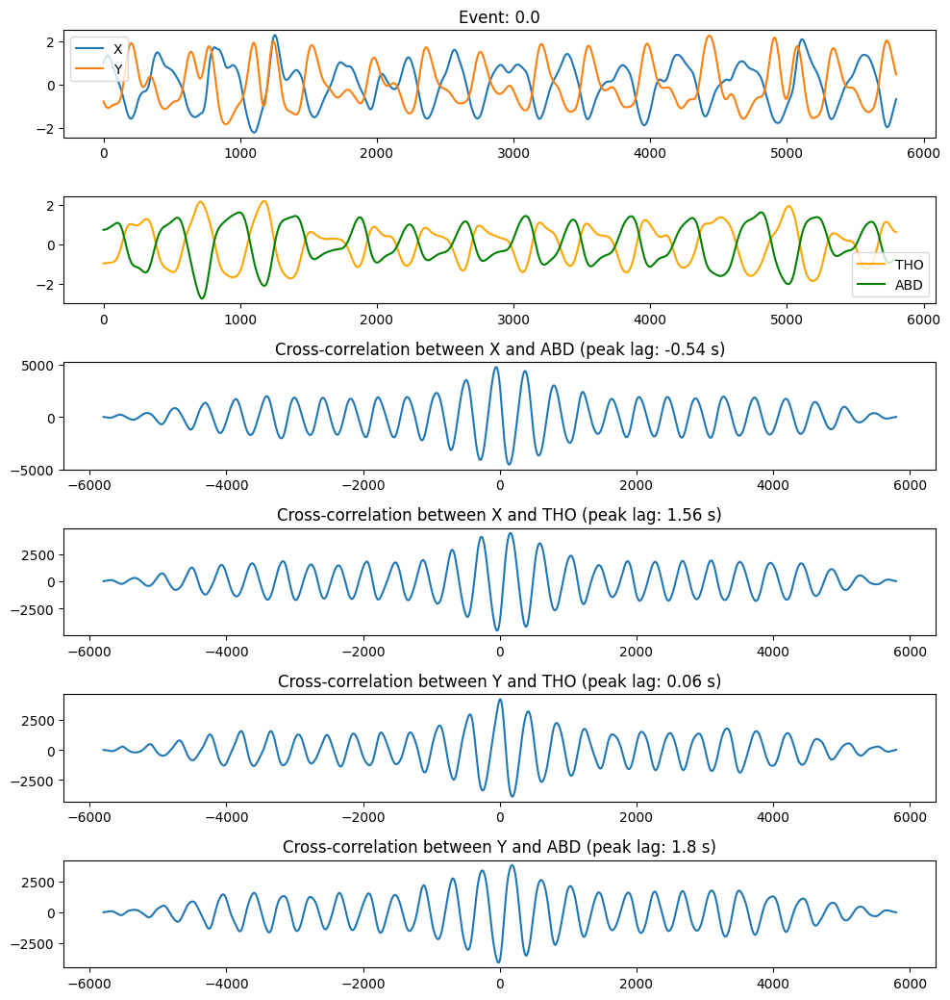

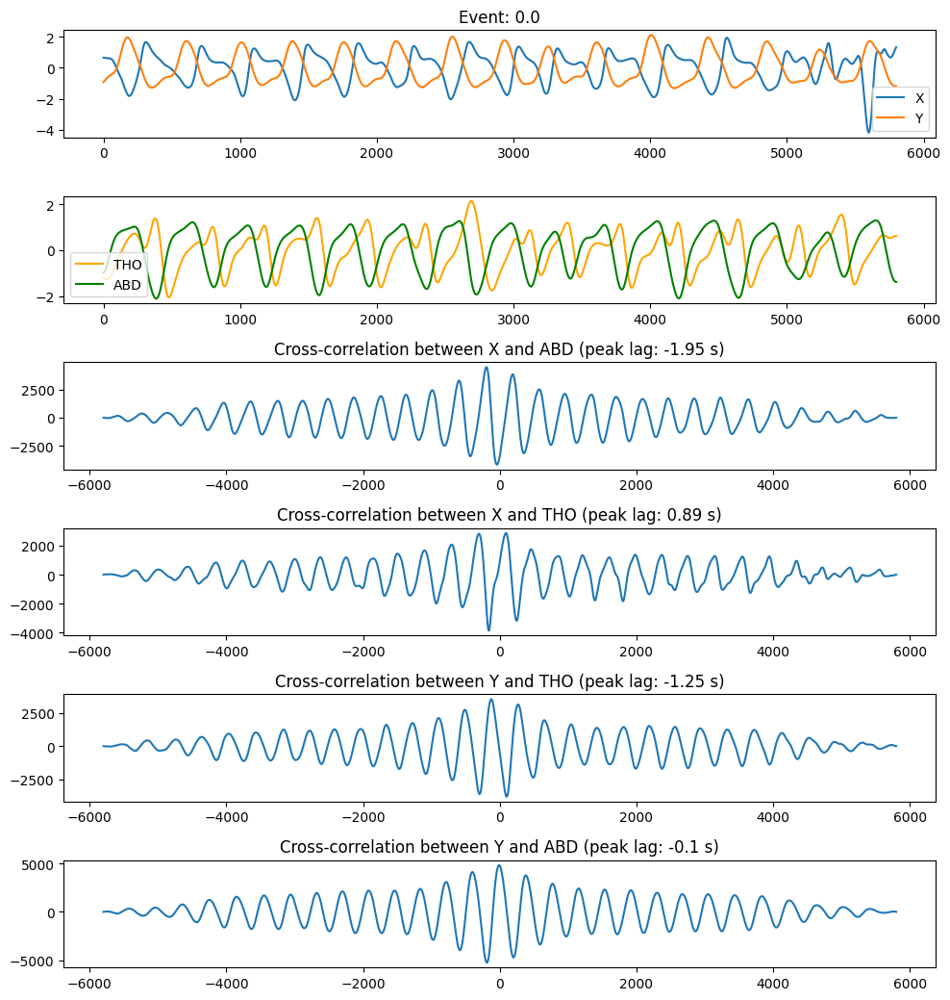

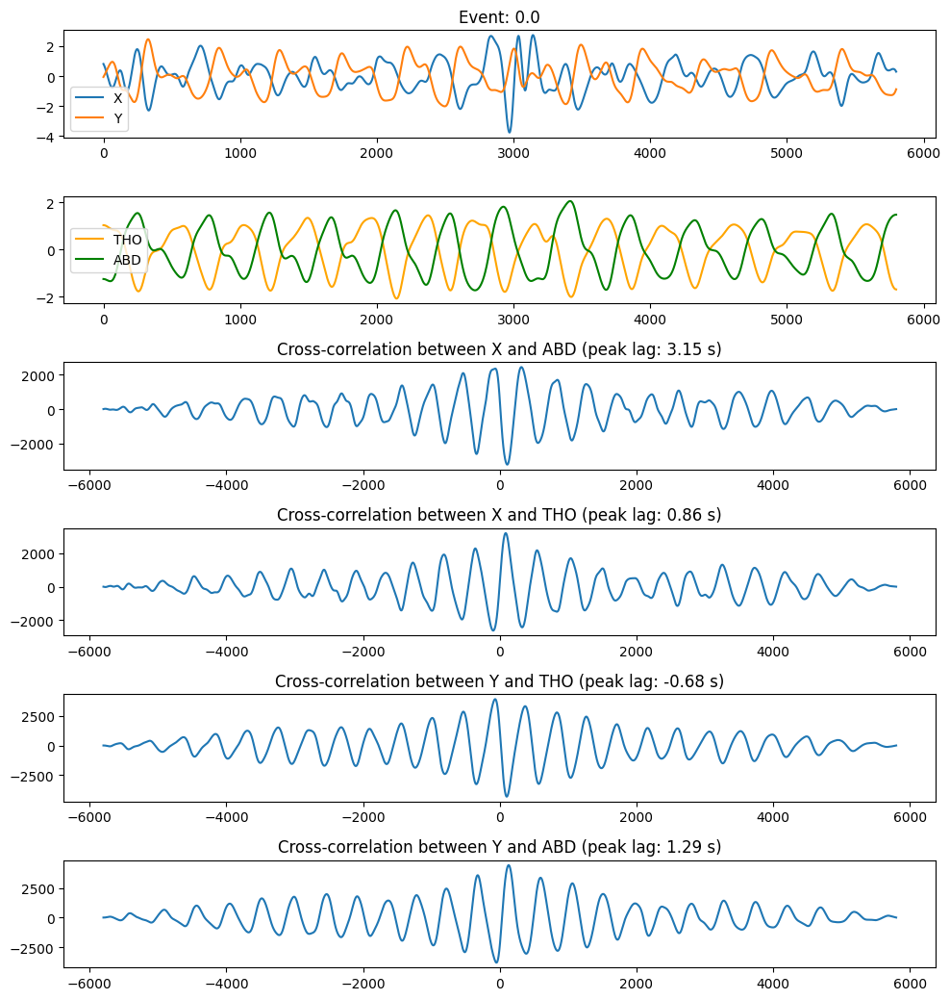

...

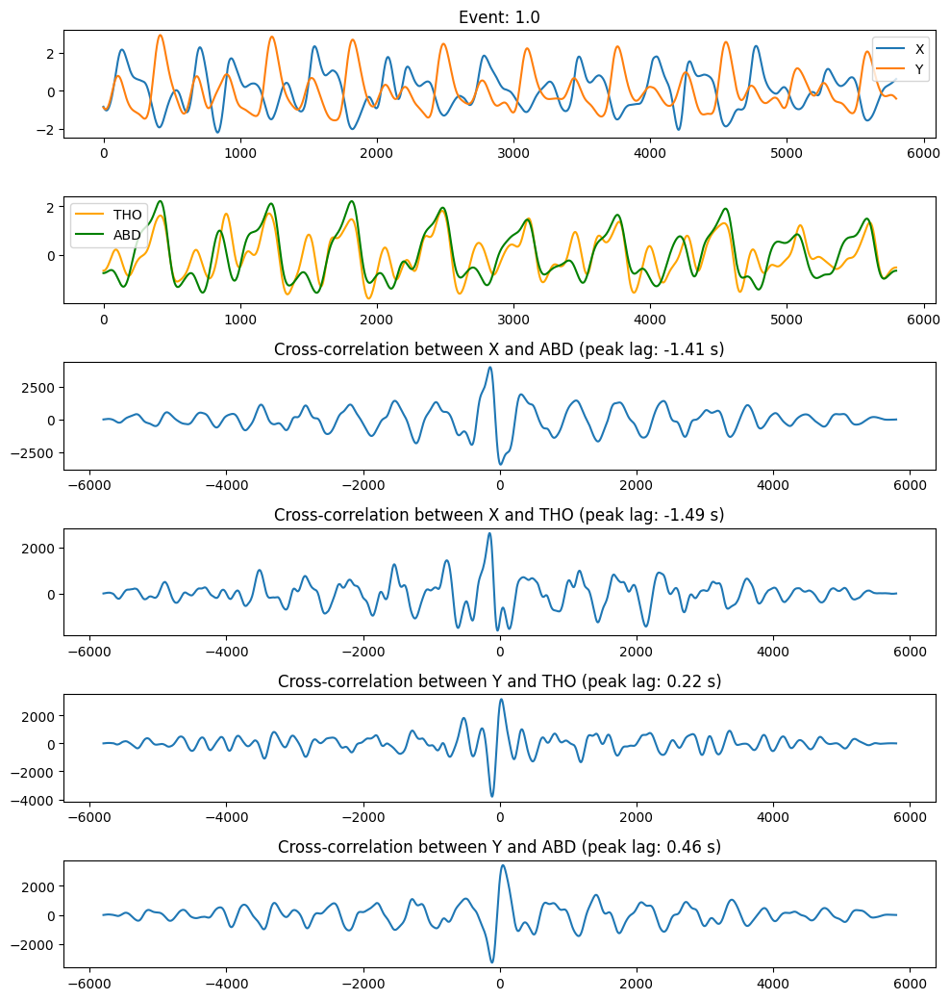

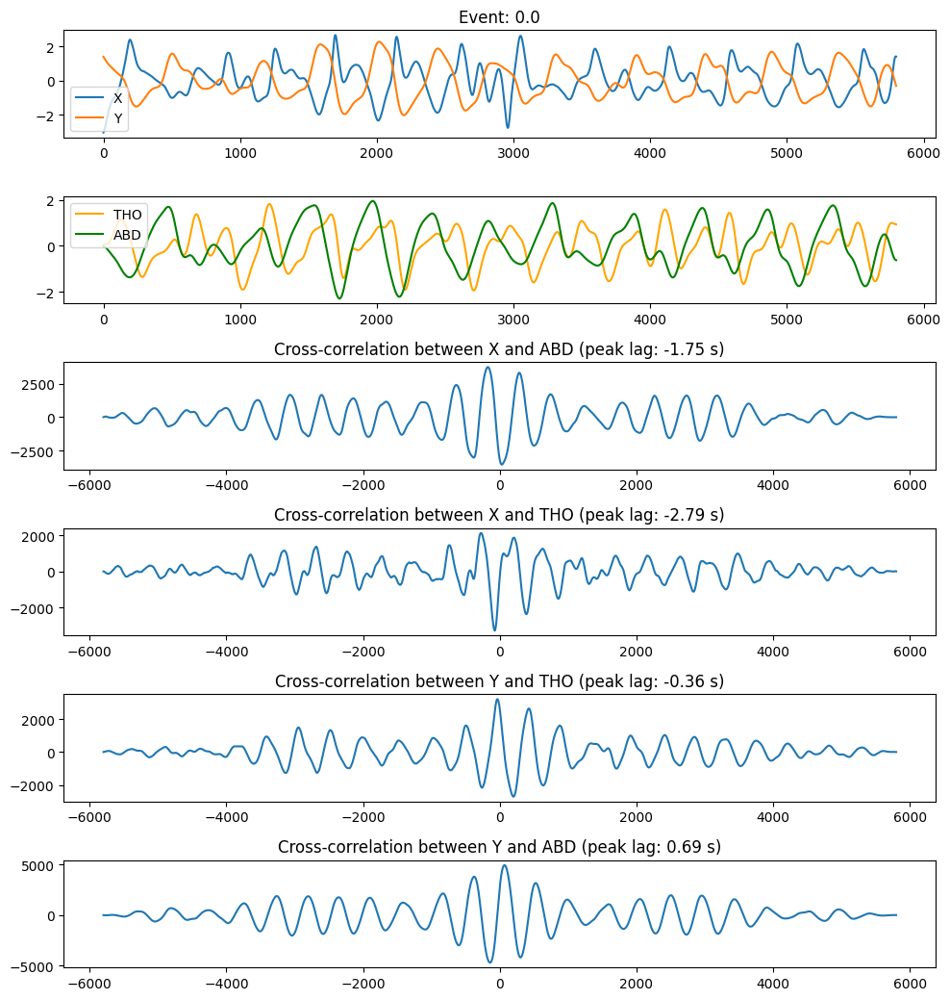

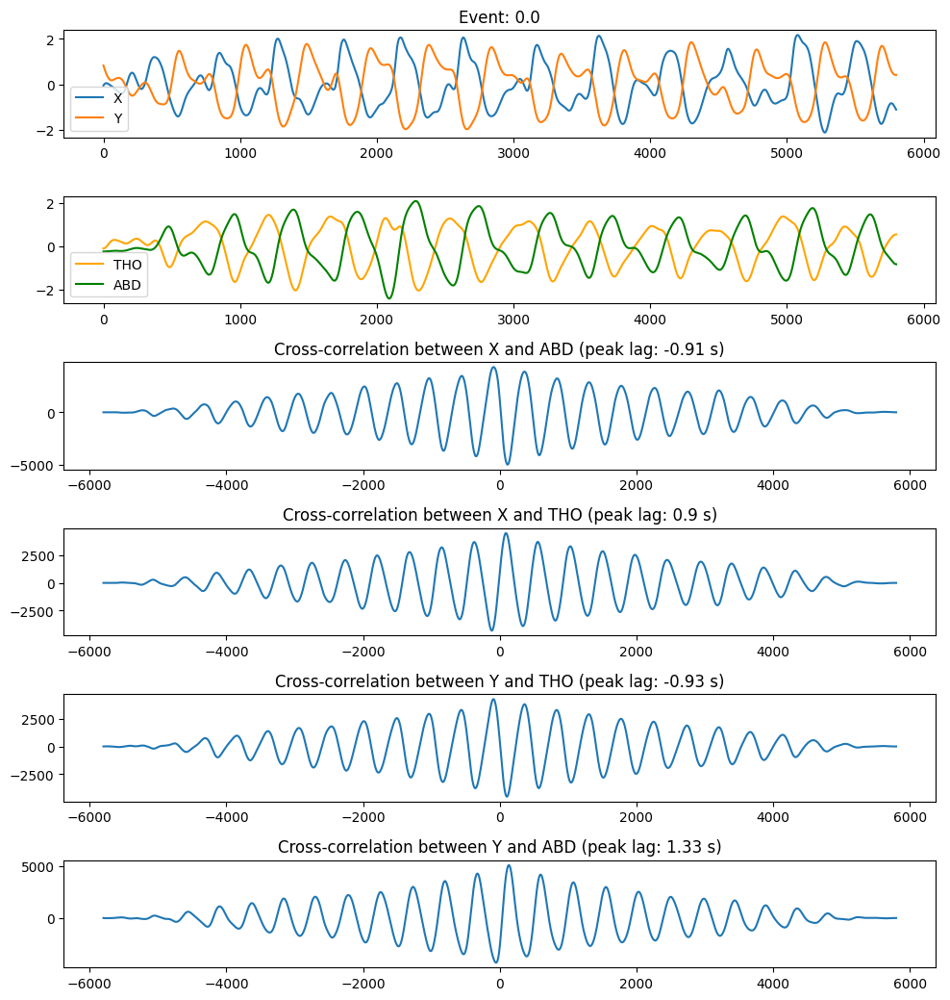

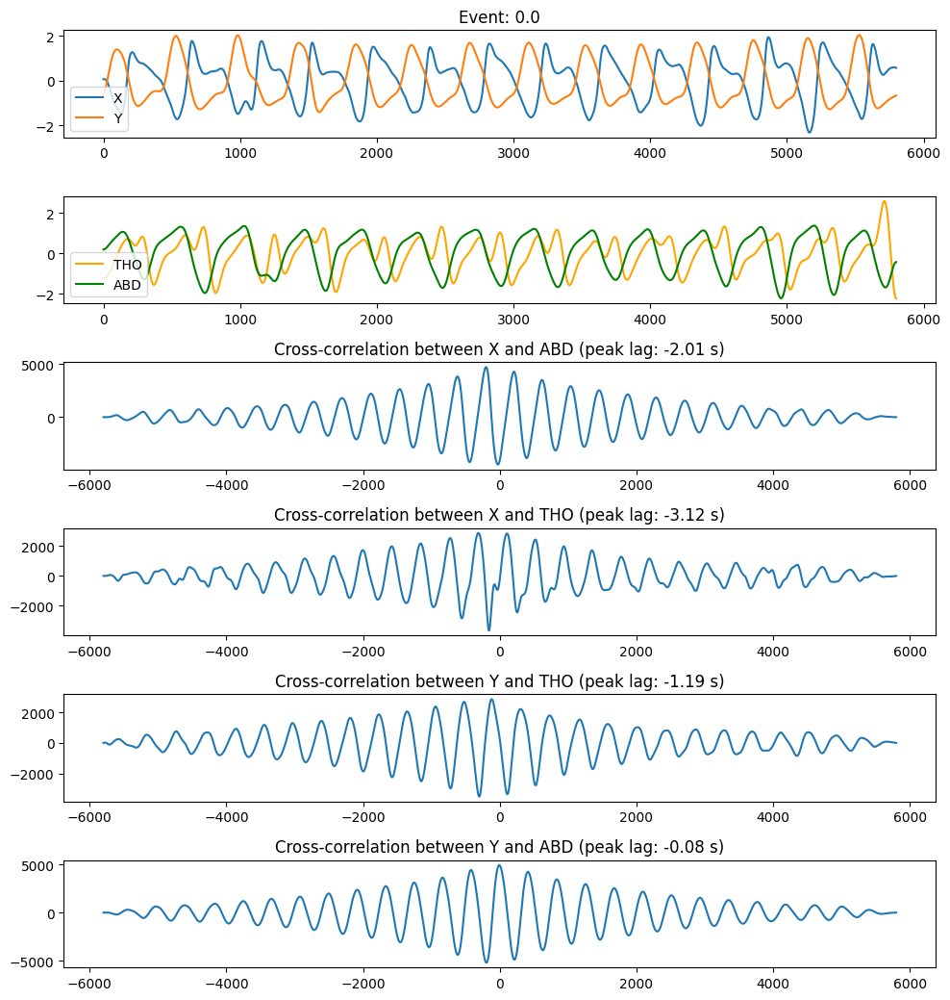

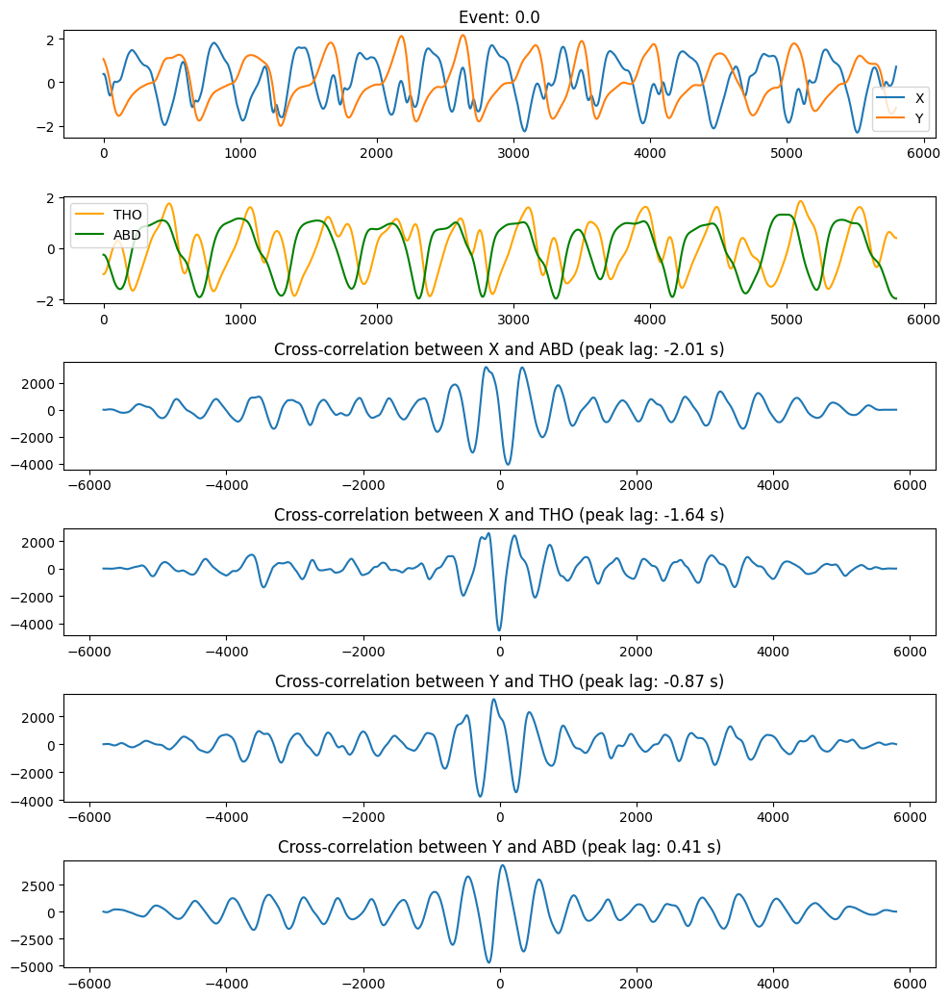

In [6]:
# 24: 1.5
# 1, 0.  
# 2: 3.2, *-1
# 3

data = all_data[all_data[:, -4] ==3]
X, Y, Z = data[:, :6000], data[:, 6000:12000], data[:, 12000:18000]
THO, ABD = data[:, 18000: 24000], data[:, 24000: 30000]
others = data[:, -6:-2]
Stages = data[:, -2]
Events = data[:, -1]
data.shape

# delay = 3.2
# X, Y, Z, THO, ABD = X[:, int(delay*100):], Y[:, int(delay*100):], Z[:, int(delay*100):], THO[:, :-int(delay*100)], ABD[:, :-int(delay*100)]


# id 30, 必须要把x和y都给*-1



from tqdm import trange

def corr_lag(x, y):
	corr = np.correlate(x, y, mode='full')
	length = len(corr)
	center = length // 2
	lags = np.arange(-center, center + 1)
	peak_lag = lags[np.argmax(corr)]
	return peak_lag, corr, lags

cross = []
# for idx in trange(len(X)):
for idx in np.random.choice(len(X), 50, replace=False):
	x, y = X[idx], Y[idx]
	tho, abd = THO[idx], ABD[idx]
	x, y = low_pass_filter(x, Fs=100, low=0.8, order=3), low_pass_filter(y, Fs=100, low=0.8, order=3)
	
	x, y, tho, abd = x[100:-100], y[100:-100], tho[100:-100], abd[100:-100]
	x, y, tho, abd = normalize_signal(x), normalize_signal(y), normalize_signal(tho), normalize_signal(abd)


	# x, y = x * -1, y * -1
	event = Events[idx]
	
	# if kurtosis(x) > 5 or kurtosis(y) > 5:
	# 	continue

	# peak_x_y, corr_x_y, lags = corr_lag(x, y)
	# peak_tho_abd, corr_tho_abd, lags = corr_lag(tho, abd)
	# if np.abs(peak_tho_abd) > 20:
	# 	continue
	# if np.abs(peak_x_y) > 20:
	# 	continue


	peak_x_abd, corr_x_abd, lags = corr_lag(x, abd)
	peak_x_tho, corr_x_tho, lags = corr_lag(x, tho)
	peak_y_tho, corr_y_tho, lags = corr_lag(y, tho)
	peak_y_abd, corr_y_abd, lags = corr_lag(y, abd)


	cross.extend([peak_x_abd, peak_x_tho, peak_y_tho, peak_y_abd])


	# if np.abs(peak_x_abd - peak_y_abd) > 10: 
	# 	continue
	# if np.abs(peak_x_tho - peak_y_tho) > 10:
	# 	continue

	
	
	row = 6
	fig, axes = plt.subplots(row, 1, figsize=(10, 1.75 * row))
	axes[0].set_title(f'Event: {Events[idx]}')
	axes[0].plot(x, label='X')
	axes[0].plot(y, label='Y')
	axes[0].legend()
	axes[1].plot(low_pass_filter(tho, Fs=100, low=0.8, order=3), color='orange')
	axes[1].plot(low_pass_filter(abd, Fs=100, low=0.8, order=3), color='green')
	axes[1].legend(['THO', 'ABD'])


	x = (x - np.mean(x)) / (np.std(x) + 1e-8)
	y = (y - np.mean(y)) / (np.std(y) + 1e-8)
	tho = (tho - np.mean(tho)) / (np.std(tho) + 1e-8)
	abd = (abd - np.mean(abd)) / (np.std(abd) + 1e-8)


	corr = np.correlate(x, abd, mode='full')


	length = len(corr)
	center = length // 2
	lags = np.arange(-center, center + 1)

	peak_lag = lags[np.argmax(corr)]
	axes[2].plot(lags, corr)
	axes[2].set_title(f'Cross-correlation between X and ABD (peak lag: {peak_lag/100} s)')
	
	corr = np.correlate(x, tho, mode='full')
	peak_lag = lags[np.argmax(corr)]
	axes[3].plot(lags, corr)
	axes[3].set_title(f'Cross-correlation between X and THO (peak lag: {peak_lag/100} s)')


	corr = np.correlate(y, tho, mode='full')
	peak_lag = lags[np.argmax(corr)]
	axes[4].plot(lags, corr)
	axes[4].set_title(f'Cross-correlation between Y and THO (peak lag: {peak_lag/100} s)')


	corr = np.correlate(y, abd, mode='full')
	peak_lag = lags[np.argmax(corr)]
	axes[5].plot(lags, corr)
	axes[5].set_title(f'Cross-correlation between Y and ABD (peak lag: {peak_lag/100} s)')

	plt.tight_layout()
	plt.show()	

# cross = np.array(cross)
# cross = cross[(cross < 500) & (cross > -500)]
# plt.hist(cross, bins=100)
# plt.xlabel("Value")
# plt.ylabel("Frequency")
# plt.title("Histogram")
# plt.show()

# counts, bin_edges = np.histogram(cross, bins=100)
# peak_bin_idx = np.argmax(counts)
# peak_value = (bin_edges[peak_bin_idx] + bin_edges[peak_bin_idx + 1]) / 2
# print(f"Peak at: {peak_value}")
